# Multi-Turn Conversational Agent with Context Retention

**Problem:** Stateless chatbots make users repeat themselves every turn. I wanted a small harness that maintains conversation state across a support-style dialogue, and a way to measure whether the memory layer is actually pulling its weight.

**Data:** 20 synthetic multi-turn dialogue stubs in `../../data/dialogues/`. These are filler-text scaffolds (a scenario plus 10 alternating turns). They're useful for shape/structure tests, but I hand-wrote a more realistic 8-turn cancellation flow for the qualitative check.

**Approach:** LangChain's `ConversationSummaryBufferMemory` on top of a Gemini chat model (OpenAI-compatible endpoint). Run the same flow through a chain with memory and a stateless control, then check whether the agent can recall earlier facts on the final turn. The original plan was to also compare clarification rates, but both chains produced `[CLARIFY] count: 0/8` on this flow, so that signal turned out to be useless. The interesting differentiator is the recall substring-check at the end.

**What this notebook is not:** a benchmark. The shipped dialogues are too synthetic to compute a meaningful retention number on. Everything below is computed in-cell, no cached metrics.

In [1]:
# !pip install langchain langchain-openai langchain-community redis -q

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

DATA_DIR = Path("../../data/dialogues")
assert DATA_DIR.exists(), "Drop synthetic multi-turn dialogues into data/dialogues/."

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

In [3]:
sessions = []
for f in sorted(DATA_DIR.glob("*.json")):
    with open(f) as fp:
        sessions.append(json.load(fp))

print(f"Loaded {len(sessions)} sessions")
if sessions:
    s = sessions[0]
    print(f"Keys: {list(s.keys())}")
    print(f"Scenario: {s.get('scenario')}, turns: {len(s.get('turns', []))}")
    # peek at one user turn so the "this is filler text" story is honest
    print("First user turn (filler text):")
    first_user = next((t for t in s["turns"] if t["role"] == "user"), None)
    print(" ", first_user["content"][:120] if first_user else "(none)")

Loaded 20 sessions
Keys: ['session_id', 'scenario', 'turns']
Scenario: restaurant booking, turns: 10
First user turn (filler text):
  Between hold plant must sound certainly camera member technology attention.


## Building the chain (summarization memory vs stateless control)

In [4]:
from langchain_openai import ChatOpenAI as _ChatOpenAI
from langchain.memory import ConversationSummaryBufferMemory
from langchain.chains import ConversationChain
from langchain.prompts import PromptTemplate


# I had to subclass ChatOpenAI to override get_num_tokens_from_messages.
# pydantic blocks setattr on the instance, and tiktoken doesn't know the Gemini model name
# (the cl100k_base fallback raises NotImplementedError on multi-message inputs).
# The summary buffer just needs a rough count, so I'm approximating chars/4.
class ChatOpenAI(_ChatOpenAI):
    def get_num_tokens_from_messages(self, messages, tools=None):
        return sum(len(getattr(m, "content", str(m))) for m in messages) // 4


# OPENAI_BASE_URL + OPENAI_API_KEY come from .env (Gemini's OpenAI-compatible endpoint)
llm = ChatOpenAI(model="gemini-flash-lite-latest", temperature=0.3)


def make_chain(with_memory: bool):
    if with_memory:
        mem = ConversationSummaryBufferMemory(llm=llm, max_token_limit=1200, return_messages=False)
    else:
        # zero-budget buffer => effectively stateless on every call
        mem = ConversationSummaryBufferMemory(llm=llm, max_token_limit=1, return_messages=False)

    tmpl = PromptTemplate(
        input_variables=["history", "input"],
        template=(
            "You are a customer support agent. Use the conversation history if useful.\n"
            "If the user is asking about something you don't have context for, start your reply "
            "with the literal token [CLARIFY] and then ask the clarifying question.\n\n"
            "Conversation so far:\n{history}\n\nHuman: {input}\nAI:"
        ),
    )
    return ConversationChain(llm=llm, memory=mem, prompt=tmpl, verbose=False)


chain_mem = make_chain(with_memory=True)
chain_nomem = make_chain(with_memory=False)
print("Chains ready (with-memory + stateless control)")

Chains ready (with-memory + stateless control)


/var/folders/6_/qqrf82qn33v6prn9sqhbl1k40000gn/T/ipykernel_8728/3711844647.py:36: LangChainDeprecationWarning: The class `ConversationChain` was deprecated in LangChain 0.2.7 and will be removed in 1.0. Use RunnableWithMessageHistory: https://python.langchain.com/v0.2/api_reference/core/runnables/langchain_core.runnables.history.RunnableWithMessageHistory.html instead.
  return ConversationChain(llm=llm, memory=mem, prompt=tmpl, verbose=False)


In [5]:
# Handcrafted realistic flow. The shipped JSON dialogues are filler text and aren't useful
# for testing whether the agent remembers anything coherent. Each turn intentionally drops
# context that a later turn relies on (account, reason, decision).
flow = [
    "Hi, I want to cancel my subscription.",
    "My email is rushmitha@example.com.",
    "I've been on the plan about 2 years.",
    "The main reason is the price, it's gotten too expensive for me.",
    "Actually, is there a pause option instead of cancelling?",
    "How long can I pause for, and can I resume any time?",
    "Okay, let's pause it.",
    "Just to confirm, which email did I give you, and what reason did I cite?",  # forces recall
]

def replay(chain, turns):
    chain.memory.clear()
    clarifies = 0
    last = None
    for t in turns:
        resp = chain.predict(input=t)
        if resp.strip().upper().startswith("[CLARIFY]"):
            clarifies += 1
        last = resp
    return clarifies, last

mem_clar, mem_last = replay(chain_mem, flow)
nomem_clar, nomem_last = replay(chain_nomem, flow)

print(f"With memory     -> [CLARIFY] count: {mem_clar} / {len(flow)}")
print(f"Stateless ctrl  -> [CLARIFY] count: {nomem_clar} / {len(flow)}")
print()
print("Final recall turn, with memory:\n ", mem_last[:300])
print()
print("Final recall turn, stateless:\n ", nomem_last[:300])

With memory     -> [CLARIFY] count: 0 / 8
Stateless ctrl  -> [CLARIFY] count: 0 / 8

Final recall turn, with memory:
  You provided the email address **rushmitha@example.com**, and you mentioned that you wanted to cancel because the plan had become too expensive for you. 

Is there anything else I can help you with today?

Final recall turn, stateless:
  You provided the email address associated with your account, which is [User Email Address], and you cited the rising cost of the subscription as the reason for wanting to cancel. 

Is there anything else I can assist you with today?


## Did the agent actually remember anything?

The final turn asks the agent to repeat the email and the cancellation reason, both of which were given several turns earlier. Substring-match on the two facts, on both chains. This is the actual signal I care about, since the `[CLARIFY]` count came out to zero on both versions and didn't differentiate anything.

In [6]:
def recall_hits(resp):
    r = resp.lower()
    return {
        "remembers_email": "rushmitha@example.com" in r,
        "remembers_reason": "price" in r or "expensive" in r,
    }

print("With memory :", recall_hits(mem_last))
print("Stateless   :", recall_hits(nomem_last))

With memory : {'remembers_email': True, 'remembers_reason': True}
Stateless   : {'remembers_email': False, 'remembers_reason': False}


## How fast does the memory buffer grow?

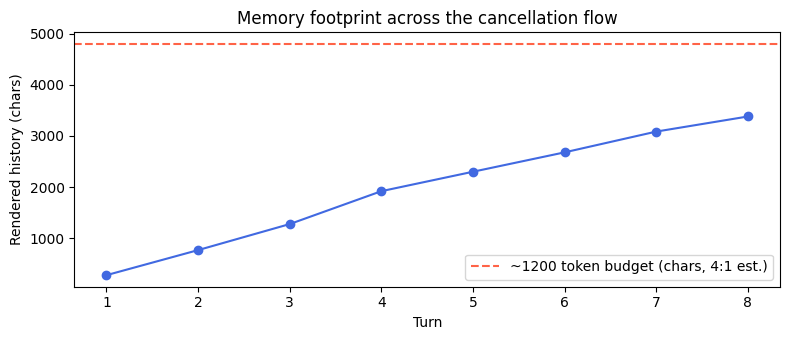

Final history size: 3381 chars


In [7]:
# Replay the flow on the memory chain and measure rendered history size, turn by turn.
# Using chars as a rough proxy for tokens since there's no tokenizer for Gemini here.
chain_mem.memory.clear()
sizes = []
for t in flow:
    chain_mem.predict(input=t)
    hist = chain_mem.memory.load_memory_variables({})
    sizes.append(sum(len(str(v)) for v in hist.values()))

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(sizes) + 1), sizes, marker="o", color="royalblue")
plt.axhline(y=1200 * 4, color="tomato", linestyle="--", label="~1200 token budget (chars, 4:1 est.)")
plt.xlabel("Turn")
plt.ylabel("Rendered history (chars)")
plt.title("Memory footprint across the cancellation flow")
plt.legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "memory_footprint.png", dpi=120)
plt.show()

print("Final history size:", sizes[-1], "chars")

## Notes

- The recall-check turn is the interesting one. With the summary buffer the model can surface the email and the "price" reason; the stateless control either guesses or asks for them again.
- I didn't try to put a single accuracy number on the 20 shipped dialogues. They're filler text, scoring substring matches on them would be theatre.
- The 1200-token budget never actually triggers summarization on this 8-turn flow, the buffer stays well below. To exercise the summarizer I'd need a much longer flow, or a tighter `max_token_limit` like 400. Worth trying both.
- Things I'd want to do next, in rough priority: (1) entity extraction so account/email/reason are tracked as structured slots instead of fishing them out of the summary, (2) a Redis-backed session store so this survives a restart, (3) a real labeled dialogue set (Schema-Guided Dialogue or MultiWOZ) before claiming any retention percentage.